(891, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Missing values per column:
Cabin          687
Age            177
Embarked         2
PassengerId      0
Name             0
Pclass           0
Survived         0
Sex              0
Parch            0
SibSp            0
Fare            

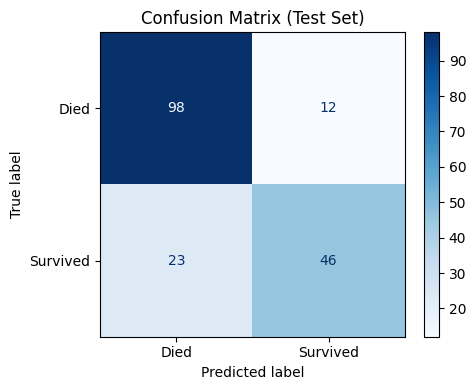

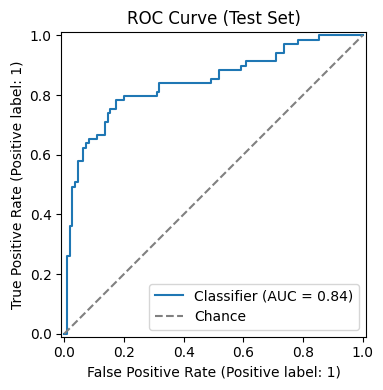

Per-fold ROC-AUC: [0.874 0.85  0.827 0.827 0.879]
CV ROC-AUC: 0.851 ± 0.022
Saved pipeline to model.joblib


,feature,coefficient
7,Sex_female,1.364351
4,Pclass_1,1.038653
10,Embarked_Q,0.348068
5,Pclass_2,0.138022
3,Fare,0.133851
9,Embarked_C,0.095733
2,Parch,-0.070794
1,SibSp,-0.261398
11,Embarked_S,-0.321817
0,Age,-0.489323


In [ ]:

import pandas as pd, numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, roc_auc_score,
                              ConfusionMatrixDisplay, RocCurveDisplay,
                              accuracy_score)
import joblib

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)



import os, urllib.request

DATA_PATH = "titanic.csv"
DATA_URL = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"

if not os.path.exists(DATA_PATH):
    print("titanic.csv not found locally — downloading...")
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)
    print("Downloaded.")

df = pd.read_csv(DATA_PATH)
print(df.shape)
df.head()



df.info()
print("\nMissing values per column:")
print(df.isna().sum().sort_values(ascending=False))


# ===== CELL 4: Select features / target =====
FEATURES = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]
TARGET = "Survived"

X = df[FEATURES].copy()
y = df[TARGET].astype(int)

num_cols = ["Age", "SibSp", "Parch", "Fare"]
cat_cols = ["Pclass", "Sex", "Embarked"]


# ===== CELL 5: Preprocessor (impute + scale/encode) =====
preprocess = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), num_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_cols),
])


# ===== CELL 6: Full pipeline (preprocessing + model) =====
pipe = Pipeline([
    ("prep", preprocess),
    ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])


# ===== CELL 7: Train/test split (stratified) =====
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Train size:", X_train.shape, " Test size:", X_test.shape)


# ===== CELL 8: Fit the model =====
pipe.fit(X_train, y_train)


# ===== CELL 9: Predict + core metrics =====
y_pred = pipe.predict(X_test)
y_proba = pipe.predict_proba(X_test)[:, 1]

acc = accuracy_score(y_test, y_pred)
test_auc = roc_auc_score(y_test, y_proba)

print(f"Accuracy: {acc:.3f}")
print(f"ROC-AUC:  {test_auc:.3f}\n")
print("Classification report:")
print(classification_report(y_test, y_pred, target_names=["Died", "Survived"]))


# ===== CELL 10: Confusion matrix =====
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Died", "Survived"], cmap="Blues", ax=ax
)
ax.set_title("Confusion Matrix (Test Set)")
plt.tight_layout()
plt.show()


# ===== CELL 11: ROC curve =====
fig, ax = plt.subplots(figsize=(5, 4))
RocCurveDisplay.from_predictions(y_test, y_proba, ax=ax)
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
ax.set_title("ROC Curve (Test Set)")
ax.legend()
plt.tight_layout()
plt.show()


# ===== CELL 12: 5-fold cross-validation (ROC-AUC) =====
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_auc = cross_val_score(pipe, X, y, cv=cv, scoring="roc_auc")
print("Per-fold ROC-AUC:", np.round(cv_auc, 3))
print(f"CV ROC-AUC: {cv_auc.mean():.3f} ± {cv_auc.std():.3f}")


# ===== CELL 13: Save + reload the model =====
joblib.dump(pipe, "model.joblib")
print("Saved pipeline to model.joblib")

reloaded_model = joblib.load("model.joblib")
sample = X_test.head(5)
sample_preds = reloaded_model.predict(sample)
sample_proba = reloaded_model.predict_proba(sample)[:, 1]

demo = sample.copy()
demo["Actual"] = y_test.head(5).values
demo["Predicted"] = sample_preds
demo["P(Survived)"] = sample_proba.round(3)
demo


# ===== CELL 14: Feature coefficients (explainability) =====
ohe_names = pipe.named_steps["prep"].named_transformers_["cat"].named_steps["ohe"] \
    .get_feature_names_out(cat_cols)
all_feature_names = np.concatenate([num_cols, ohe_names])
coefs = pipe.named_steps["clf"].coef_[0]

coef_df = pd.DataFrame({"feature": all_feature_names, "coefficient": coefs}) \
    .sort_values("coefficient", ascending=False)
coef_df